| **Inicio**         | **atrás 2**                          | **Siguiente 4**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./3_2_Distribuciones.ipynb) | [⏩](./3_4_Probabilidad_para_ML.ipynb) |

# 1. Media

La **media aritmética** es una medida de tendencia central.

Si tenemos datos

$$
x_1,x_2,\ldots,x_n
$$

la media muestral es

$$
\boxed{\bar{x}=\frac{1}{n}\sum_{i=1}^n x_i}
$$

## Ejemplo sencillo

Supongamos que medimos la temperatura de un reactor:

$$
T=[98,101,99,102,100]
$$

Entonces

$$
\bar T=
\frac{98+101+99+102+100}{5}
=100
$$

La temperatura promedio es

$$
\boxed{100^\circ C}
$$

## Ejemplo más difícil

Supongamos que tenemos mediciones de concentración de un contaminante:

$$
x=
[2.1,2.4,1.9,2.3,2.2,2.5,8.7]
$$

Calculamos:

$$
\bar{x}
=
\frac{2.1+2.4+1.9+2.3+2.2+2.5+8.7}{7}
$$

$$
\bar{x}=3.157
$$

Pero observa algo importante:

La mayoría de las mediciones están alrededor de 2, pero existe un valor de 8.7.

La media se desplazó considerablemente.

Esto introduce una idea fundamental:

> **La media es sensible a valores extremos.**

# 2. Mediana

La mediana es el valor que queda en el centro después de ordenar los datos.

Ejemplo:

$$
[2,4,7,8,10]
$$

La mediana es

$$
\boxed{7}
$$

Si tenemos cantidad par:

$$
[2,4,7,8,10,12]
$$

entonces

$$
\operatorname{mediana}
=
\frac{7+8}{2}
=
7.5
$$

## Media vs mediana con valores extremos

Consideremos:

$$
[2,2.1,2.2,2.3,2.4,8.7]
$$

Media:

$$
\bar{x}=3.283
$$

Mediana:

$$
\tilde{x}=\frac{2.2+2.3}{2}=2.25
$$

La mediana representa mucho mejor el "centro típico" de los datos.

### ¿Cuándo usar cada una?

| Situación                                              | Mejor medida |
| ------------------------------------------------------ | ------------ |
| Datos aproximadamente simétricos                       | Media        |
| Muchos valores extremos                                | Mediana      |
| Distribución normal                                    | Media        |
| Salarios con multimillonarios                          | Mediana      |
| Tiempos de respuesta con outliers                      | Mediana      |
| Mediciones físicas con ruido aproximadamente gaussiano | Media        |

## Python: media y mediana

Media: 3.283333333333333
Mediana: 2.25


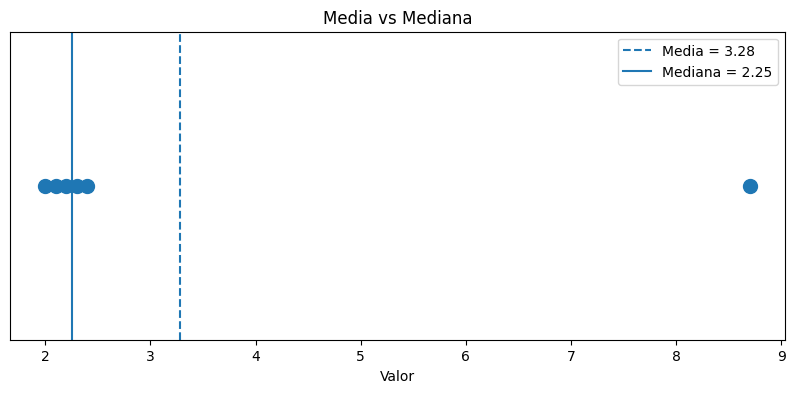

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([2, 2.1, 2.2, 2.3, 2.4, 8.7])

media = np.mean(x)
mediana = np.median(x)

print("Media:", media)
print("Mediana:", mediana)

plt.figure(figsize=(10, 4))

plt.scatter(x, np.zeros_like(x), s=100)

plt.axvline(media, linestyle="--", label=f"Media = {media:.2f}")
plt.axvline(mediana, linestyle="-", label=f"Mediana = {mediana:.2f}")

plt.yticks([])
plt.xlabel("Valor")
plt.title("Media vs Mediana")
plt.legend()
plt.show()

# 3. Varianza

Ahora llegamos a algo mucho más importante para SciML.

La media nos dice:

> ¿Dónde está el centro?

La varianza nos dice:

> **¿Qué tan dispersos están los datos alrededor del centro?**

Para una población:

$$
\boxed{
\sigma^2=
\frac{1}{N}
\sum_{i=1}^{N}(x_i-\mu)^2
}
$$

Para una muestra:

$$
\boxed{
s^2=
\frac{1}{n-1}
\sum_{i=1}^{n}(x_i-\bar{x})^2
}
$$

El $(n-1)$ es importante. Se llama **corrección de Bessel**.

## ¿Por qué elevamos al cuadrado?

Porque si simplemente sumáramos:

$$
\sum(x_i-\bar{x})
$$

siempre obtendríamos aproximadamente cero.

Ejemplo:

$$
[8,10,12]
$$

media:

$$
\bar{x}=10
$$

desviaciones:

$$
[-2,0,2]
$$

La suma es:

$$
-2+0+2=0
$$

Pero queremos medir cuánto se alejan.

Por eso:

$$
(-2)^2+0^2+2^2=8
$$

y

$$
s^2=\frac{8}{2}=4
$$

## Desviación estándar

La varianza está en unidades cuadradas.

Si medimos temperatura en °C:

$$
Var(T)
$$

está en

$$
^\circ C^2
$$

Por eso normalmente usamos:

$$
\boxed{s=\sqrt{s^2}}
$$

que es la **desviación estándar**.

## Ejemplo científico

Supongamos dos sensores.

Sensor A:

$$
[99,100,101,100,100]
$$

Sensor B:

$$
[80,110,95,105,110]
$$

Ambos pueden tener medias similares, pero el segundo es mucho más inestable.

Esto es exactamente lo que la varianza permite cuantificar.

## Python

Varianza A: 0.5
Varianza B: 162.5


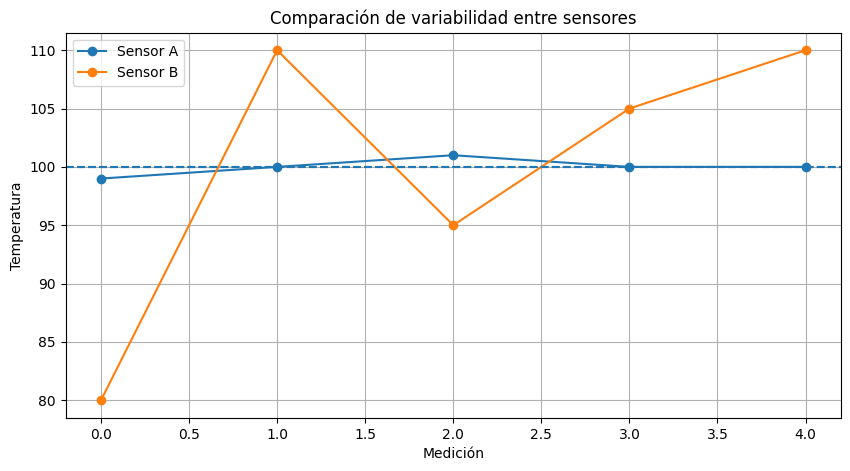

In [2]:
import numpy as np
import matplotlib.pyplot as plt

sensor_A = np.array([99, 100, 101, 100, 100])
sensor_B = np.array([80, 110, 95, 105, 110])

print("Varianza A:", np.var(sensor_A, ddof=1))
print("Varianza B:", np.var(sensor_B, ddof=1))

plt.figure(figsize=(10, 5))

plt.plot(sensor_A, "o-", label="Sensor A")
plt.plot(sensor_B, "o-", label="Sensor B")

plt.axhline(np.mean(sensor_A), linestyle="--")
plt.axhline(np.mean(sensor_B), linestyle="--")

plt.xlabel("Medición")
plt.ylabel("Temperatura")
plt.title("Comparación de variabilidad entre sensores")
plt.legend()
plt.grid()
plt.show()

# 4. Covarianza


Ahora damos un salto importante.

La varianza analiza **una variable**.

La covarianza analiza **dos variables**.

Supongamos que tenemos:

* temperatura $(T)$
* presión $(P)$

Queremos saber:

> Cuando aumenta la temperatura, ¿la presión tiende a aumentar o disminuir?

La covarianza muestral es:

$$
\boxed{
s_{XY}
=
\frac{1}{n-1}
\sum_{i=1}^{n}
(x_i-\bar{x})(y_i-\bar{y})
}
$$

## Interpretación

### Covarianza positiva

$$
Cov(X,Y)>0
$$

Cuando $(X)$ aumenta, $(Y)$ tiende a aumentar.

### Covarianza negativa

$$
Cov(X,Y)<0
$$

Cuando $(X)$ aumenta, $(Y)$ tiende a disminuir.

### Cerca de cero

$$
Cov(X,Y)\approx0
$$

No existe una relación lineal clara.

**Pero cuidado:** covarianza cero no significa necesariamente independencia.

# 5. Ejemplo difícil de covarianza

Supongamos:

$$
X=[1,2,3,4,5]
$$

y

$$
Y=[2,4,5,8,10]
$$

Media:

$$
\bar X=3
$$

$$
\bar Y=5.8
$$

Construimos:

| $(X)$ | $(Y)$ | $(X-\bar X)$ | $(Y-\bar Y)$ | Producto |
| ----: | ----: | -----------: | -----------: | -------: |
|     1 |     2 |           -2 |         -3.8 |      7.6 |
|     2 |     4 |           -1 |         -1.8 |      1.8 |
|     3 |     5 |            0 |         -0.8 |        0 |
|     4 |     8 |            1 |          2.2 |      2.2 |
|     5 |    10 |            2 |          4.2 |      8.4 |

Entonces:

$$
Cov(X,Y)
=
\frac{7.6+1.8+0+2.2+8.4}{4}
$$

$$
\boxed{Cov(X,Y)=5}
$$

Es positiva.

# 6. Correlación

Aquí aparece una herramienta mucho más interpretable.

La correlación de Pearson es:

$$
\boxed{
\rho_{XY}
=
\frac{Cov(X,Y)}
{\sigma_X\sigma_Y}
}
$$

Su valor está entre:

$$
\boxed{-1\leq\rho\leq1}
$$

Interpretación:

| $(\rho)$ | Interpretación                    |
| -------: | --------------------------------- |
|    $(1)$ | relación lineal positiva perfecta |
|  $(0.8)$ | positiva fuerte                   |
|  $(0.5)$ | moderada                          |
|    $(0)$ | sin relación lineal               |
| $(-0.5)$ | negativa moderada                 |
|   $(-1)$ | negativa perfecta                 |


## Ejemplo científico

Supongamos que estudiamos:

$$
X=\text{temperatura}
$$

$$
Y=\text{consumo energético}
$$

Obtenemos:

$$
\rho=0.91
$$

Existe una relación lineal positiva fuerte.

Pero:

> **correlación no implica causalidad.**

Por ejemplo, temperatura y consumo eléctrico pueden estar correlacionados porque ambas dependen de otra variable.

## Python: covarianza y correlación

Covarianza: 1141.6666666666665
Correlación: 0.9718512059495712


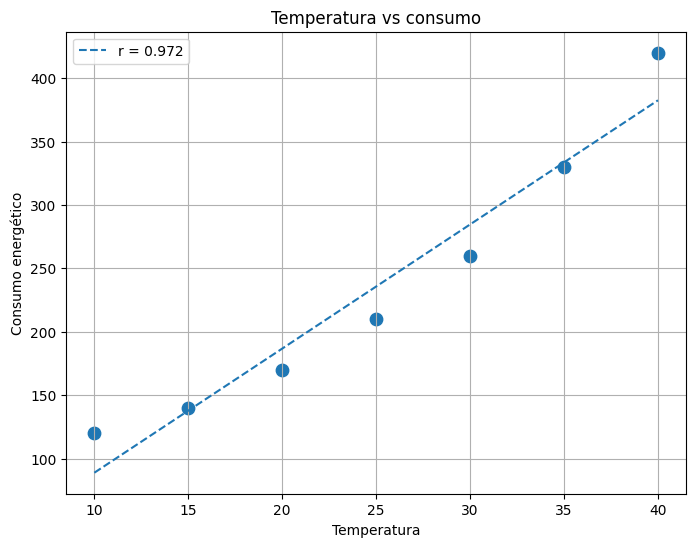

In [3]:
import numpy as np
import matplotlib.pyplot as plt

temperatura = np.array([10, 15, 20, 25, 30, 35, 40])
consumo = np.array([120, 140, 170, 210, 260, 330, 420])

cov = np.cov(temperatura, consumo, ddof=1)[0, 1]
corr = np.corrcoef(temperatura, consumo)[0, 1]

print("Covarianza:", cov)
print("Correlación:", corr)

plt.figure(figsize=(8, 6))

plt.scatter(temperatura, consumo, s=80)

coef = np.polyfit(temperatura, consumo, 1)
x_line = np.linspace(10, 40, 100)
y_line = np.polyval(coef, x_line)

plt.plot(
    x_line,
    y_line,
    linestyle="--",
    label=f"r = {corr:.3f}"
)

plt.xlabel("Temperatura")
plt.ylabel("Consumo energético")
plt.title("Temperatura vs consumo")
plt.legend()
plt.grid()
plt.show()

# 7. Algo MUY importante: correlación lineal

Supongamos:

$$
Y=X^2
$$

Entonces existe una relación perfecta entre $(X)$ y $(Y)$.

Pero si $(X)$ está distribuida simétricamente alrededor de cero, Pearson puede producir:

$$
\rho\approx0
$$

aunque claramente:

$$
Y=X^2
$$

depende de $(X)$.

Esto demuestra:

$$
\boxed{\text{correlación de Pearson mide relación lineal}}
$$

No mide cualquier tipo de dependencia.

# 8. Momentos

Ahora entramos en un concepto más profundo.

Los **momentos** describen diferentes características de una distribución.

El momento de orden $(k)$ respecto al origen es:

$$
\boxed{
E[X^k]
}
$$

Por ejemplo:

### Primer momento

$$
E[X]
$$

es la media.

### Segundo momento

$$
E[X^2]
$$

está relacionado con la varianza:

$$
\boxed{
Var(X)=E[X^2]-E[X]^2
}
$$

### Momentos centrales

Son:

$$
\boxed{
\mu_k=E[(X-\mu)^k]
}
$$

# 9. Segundo momento

$$
\mu_2=E[(X-\mu)^2]
$$

es precisamente la varianza.

# 10. Tercer momento: asimetría

El tercer momento central:

$$
\mu_3=E[(X-\mu)^3]
$$

permite estudiar la **asimetría**.

La asimetría estandarizada es:

$$
\boxed{
\gamma_1=
\frac{\mu_3}{\sigma^3}
}
$$

Interpretación aproximada:

* $(\gamma_1>0)$: cola hacia la derecha
* $(\gamma_1<0)$: cola hacia la izquierda
* $(\gamma_1\approx0)$: aproximadamente simétrica

# 11. Cuarto momento: curtosis

El cuarto momento central:

$$
\mu_4=E[(X-\mu)^4]
$$

se utiliza para estudiar el peso de las colas.

Curtosis:

$$
\boxed{
\gamma_2=\frac{\mu_4}{\sigma^4}
}
$$

En estadística también es común usar **exceso de curtosis**:

$$
\gamma_2-3
$$

porque la distribución normal tiene curtosis 3.

## ¿Por qué importan los momentos en SciML?

Porque cuando estudias incertidumbre puedes tener:

$$
u(x,t,\theta)
$$

donde $(\theta)$ representa parámetros inciertos.

Puedes querer calcular:

$$
E[u]
$$

$$
Var(u)
$$

$$
Skew(u)
$$

$$
Kurt(u)
$$

Por ejemplo:

> ¿Cuál es la temperatura promedio de un reactor?

pero también:

> ¿Cuál es la probabilidad de que la temperatura tenga una cola extrema?

Eso ya es **Uncertainty Quantification**.

## Python: momentos

Media: 4.029337235825146
Varianza: 8.172272411989269
Asimetría: 1.4443017535954497
Exceso de curtosis: 3.2424841290899113


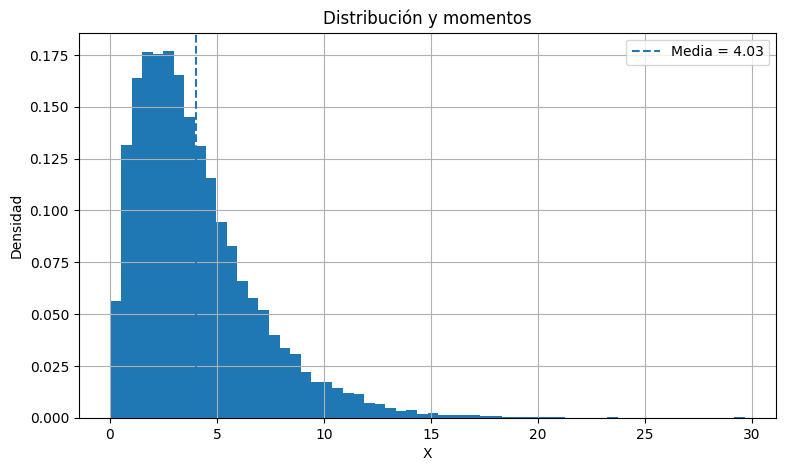

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis

rng = np.random.default_rng(42)

x = rng.gamma(
    shape=2.0,
    scale=2.0,
    size=10000
)

mu = np.mean(x)
var = np.var(x, ddof=1)
sk = skew(x)
ku = kurtosis(x)

print("Media:", mu)
print("Varianza:", var)
print("Asimetría:", sk)
print("Exceso de curtosis:", ku)

plt.figure(figsize=(9, 5))

plt.hist(x, bins=60, density=True)

plt.axvline(mu, linestyle="--", label=f"Media = {mu:.2f}")

plt.xlabel("X")
plt.ylabel("Densidad")
plt.title("Distribución y momentos")
plt.legend()
plt.grid()
plt.show()

# 12. Estimación

Ahora entramos en estadística inferencial.

Supongamos que existe una población enorme.

No podemos medir todo.

Queremos estimar un parámetro desconocido.

Por ejemplo:

$$
\mu=\text{temperatura media real}
$$

pero solamente tenemos:

$$
X_1,\ldots,X_n
$$

Entonces usamos un **estimador**.

Por ejemplo:

$$
\boxed{\hat{\mu}=\bar X}
$$

# 13. Parámetro vs estadístico

Esto es fundamental.

### Parámetro

Característica verdadera de la población:

$$
\mu,\sigma^2,p
$$

### Estadístico

Calculado a partir de la muestra:

$$
\bar X,s^2,\hat p
$$

Ejemplo:

Una fábrica tiene millones de piezas.

La verdadera tasa de defectos podría ser:

$$
p=0.0187
$$

pero no conocemos $(p)$.

Tomamos una muestra de 1000 piezas.

Encontramos 23 defectuosas:

$$
\hat p=\frac{23}{1000}=0.023
$$

Nuestro estimador es:

$$
\boxed{\hat p=0.023}
$$

# 14. Estimación puntual

Una estimación puntual produce un solo número.

Ejemplos:

$$
\hat{\mu}=\bar{x}
$$

$$
\hat{\sigma}^2=s^2
$$

$$
\hat{p}=\frac{x}{n}
$$

# 15. Máxima verosimilitud

Esto será **muy importante para SciML**.

Supongamos:

$$
X_i\sim N(\mu,\sigma^2)
$$

Tenemos datos:

$$
x_1,\ldots,x_n
$$

La función de verosimilitud es:

$$
L(\mu,\sigma)
=
\prod_{i=1}^{n}
f(x_i|\mu,\sigma)
$$

Normalmente trabajamos con log-verosimilitud:

$$
\ell(\mu,\sigma)
=
\log L(\mu,\sigma)
$$

Y buscamos:

$$
\boxed{
(\hat{\mu},\hat{\sigma})
=
\arg\max_{\mu,\sigma}
\ell(\mu,\sigma)
}
$$

En muchos modelos, esto se convierte en un problema de optimización.

Y aquí aparece directamente:

$$
\boxed{
\text{Estadística}
\rightarrow
\text{Optimización}
\rightarrow
\text{Machine Learning}
\rightarrow
\text{SciML}
}
$$

# 16. Ejemplo de estimación en un modelo físico

Supongamos el modelo:

$$
T(t)=T_0e^{-kt}
$$

Este puede representar enfriamiento simplificado.

Tenemos datos experimentales:

$$
(t_i,T_i)
$$

pero desconocemos $(k)$.

Queremos estimarlo.

Podemos plantear:

$$
\boxed{
\hat{k}
=
\arg\min_k
\sum_i
[T_i-T_0e^{-kt_i}]^2
}
$$

Esto es **estimación de parámetros de un modelo físico**.

Es uno de los problemas centrales de SciML.

# 17. Intervalos de confianza

Una estimación puntual no nos dice cuánta incertidumbre existe.

Si decimos:

$$
\hat{\mu}=100
$$

¿qué tan seguros estamos?

Quizás:

$$
100\pm0.5
$$

o:

$$
100\pm20
$$

son situaciones completamente diferentes.

## Intervalo de confianza

Un intervalo de confianza del 95% para una media, bajo condiciones apropiadas, puede escribirse como:

$$
\boxed{
\bar{x}
\pm
t_{0.975,n-1}
\frac{s}{\sqrt n}
}
$$

donde:

* $(\bar{x})$ = media
* $(s)$ = desviación estándar
* $(n)$ = tamaño de muestra
* $(t)$ = cuantíl de Student.

# 18. Ejemplo difícil

Tenemos 25 mediciones de una máquina.

$$
\bar{x}=52.4
$$

$$
s=3.2
$$

$$
n=25
$$

Para 95%:

$$
t_{0.975,24}\approx2.064
$$

Error estándar:

$$
SE=\frac{3.2}{\sqrt{25}}
=0.64
$$

Margen:

$$
2.064(0.64)=1.322
$$

Por tanto:

$$
\boxed{
52.4\pm1.322
}
$$

o:

$$
\boxed{
[51.078,\;53.722]
}
$$

# 19. Interpretación correcta

Un error extremadamente común es decir:

> "Hay 95% de probabilidad de que el parámetro esté dentro de este intervalo."

En la interpretación frecuentista clásica, eso **no es correcto**.

El parámetro es fijo; el intervalo es aleatorio antes de observar los datos.

La interpretación correcta es:

> Si repitiéramos el procedimiento de muestreo muchas veces y construyéramos un intervalo del mismo modo, aproximadamente el 95% de esos intervalos contendrían el verdadero parámetro.

Esto será importante cuando llegues a **Bayesian inference**, donde la interpretación cambia.

# 20. Python: intervalo de confianza

Media: 100.13451296646174
IC 95%: (np.float64(97.81417001133534), np.float64(102.45485592158815))


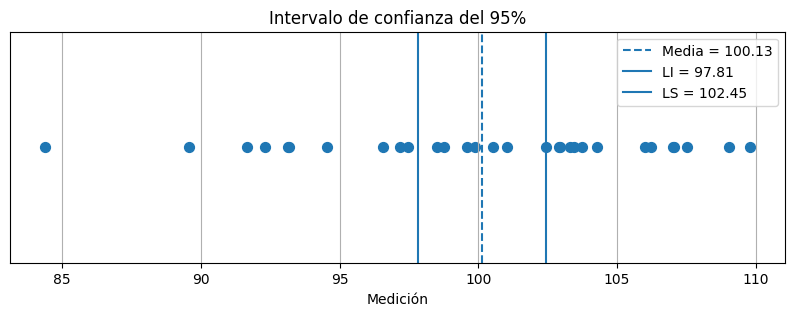

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

datos = rng.normal(
    loc=100,
    scale=8,
    size=30
)

n = len(datos)
media = np.mean(datos)
s = np.std(datos, ddof=1)

alpha = 0.05

t_critico = stats.t.ppf(
    1 - alpha / 2,
    df=n - 1
)

error = t_critico * s / np.sqrt(n)

li = media - error
ls = media + error

print("Media:", media)
print("IC 95%:", (li, ls))

plt.figure(figsize=(10, 3))

plt.scatter(datos, np.zeros(n), s=50)

plt.axvline(media, linestyle="--",
            label=f"Media = {media:.2f}")

plt.axvline(li, linestyle="-",
            label=f"LI = {li:.2f}")

plt.axvline(ls, linestyle="-",
            label=f"LS = {ls:.2f}")

plt.yticks([])
plt.xlabel("Medición")
plt.title("Intervalo de confianza del 95%")
plt.legend()
plt.grid()
plt.show()

# 21. ¿Qué pasa si aumenta $(n)$?

Observa:

$$
SE=\frac{s}{\sqrt n}
$$

Por tanto:

$$
n\uparrow
\quad\Rightarrow\quad
SE\downarrow
$$

y el intervalo se hace más estrecho.

Esto explica por qué recolectar más datos generalmente mejora nuestra estimación.

Pero existe una advertencia:

> Más datos no corrigen un modelo sesgado.

Si tu sensor está mal calibrado, tener un millón de mediciones no necesariamente soluciona el problema.

# 22. Pruebas de hipótesis

Ahora queremos tomar decisiones.

Ejemplo:

Una máquina debería producir piezas con:

$$
\mu=100\text{ mm}
$$

Sospechamos que se ha descalibrado.

Planteamos:

$$
H_0:\mu=100
$$

$$
H_1:\mu\neq100
$$

donde:

### $(H_0)$

Hipótesis nula.

### $(H_1)$

Hipótesis alternativa.

# 23. Estadístico de prueba

Si conocemos la desviación poblacional $(\sigma)$:

$$
\boxed{
Z=
\frac{\bar X-\mu_0}
{\sigma/\sqrt n}
}
$$

Si $(\sigma)$ es desconocida usamos:

$$
\boxed{
t=
\frac{\bar X-\mu_0}
{s/\sqrt n}
}
$$

# 24. Ejemplo

Supongamos:

$$
n=36
$$

$$
\bar{x}=102.1
$$

$$
s=4.8
$$

Queremos comprobar:

$$
H_0:\mu=100
$$

contra:

$$
H_1:\mu\neq100
$$

Calculamos:

$$
t=
\frac{102.1-100}{4.8/\sqrt{36}}
$$

$$
t=
\frac{2.1}{0.8}
$$

$$
\boxed{t=2.625}
$$

Ahora obtenemos el $(p)$-valor.

In [6]:
import scipy.stats as stats

t = 2.625
df = 35

p_value = 2 * stats.t.sf(abs(t), df)

print("p-value:", p_value)

p-value: 0.012759681031537072


Aproximadamente:

$$
p\approx0.0127
$$

Si usamos:

$$
\alpha=0.05
$$

tenemos:

$$
p<\alpha
$$

por lo que rechazamos $(H_0)$.

# 25. ¿Qué significa el p-value?

Otra confusión extremadamente común.

El $(p)$-valor **no es**:

$$
P(H_0\text{ es verdadera})
$$

Esencialmente representa:

> La probabilidad, suponiendo $(H_0)$ verdadera, de obtener un resultado al menos tan extremo como el observado.

Por eso:

$$
p<0.05
$$

no significa:

> "Hay 95% de probabilidad de que mi hipótesis sea correcta."

# 26. Error tipo I y tipo II

Esto es muy importante en ciencia.

### Error tipo I

Rechazamos $(H_0)$ cuando era verdadera.

$$
\boxed{\text{Falso positivo}}
$$

Su probabilidad se controla mediante:

$$
\alpha
$$

### Error tipo II

No rechazamos $(H_0)$ cuando era falsa.

$$
\boxed{\text{Falso negativo}}
$$

Su probabilidad es:

$$
\beta
$$

y la potencia estadística es:

$$
\boxed{1-\beta}
$$

# 27. Ejemplo médico

Supongamos una prueba para detectar una enfermedad.

$$
H_0:\text{persona sana}
$$

$$
H_1:\text{persona enferma}
$$

Entonces:

### Tipo I

La prueba dice enfermo cuando está sano.

**Falso positivo.**

### Tipo II

La prueba dice sano cuando está enfermo.

**Falso negativo.**

En medicina, seguridad industrial, detección de fraude y monitoreo de sistemas, ambos errores tienen costos diferentes.

# 28. Ejemplo de hipótesis en SciML

Aquí empieza a ponerse realmente interesante.

Supongamos que tenemos un modelo físico:

$$
\frac{du}{dt}=-ku
$$

y datos experimentales.

Queremos determinar si:

$$
k=0.5
$$

es compatible con los datos.

Podemos plantear:

$$
H_0:k=0.5
$$

versus

$$
H_1:k\neq0.5
$$

Estimamos:

$$
\hat{k}
$$

y su incertidumbre.

Entonces podemos construir:

$$
CI_{95\%}(k)
$$

Si el valor $(0.5)$ queda fuera del intervalo, tenemos evidencia contra $(H_0)$.

Esto es:

$$
\boxed{
\text{modelo físico}
+
\text{datos}
+
\text{estadística}
}
$$

y constituye una parte importante de **Scientific Machine Learning**.

# 29. Un ejemplo SciML completo

Supongamos:

$$
\frac{du}{dt}=-ku
$$

con:

$$
u(0)=100
$$

La solución exacta:

$$
\boxed{
u(t)=100e^{-kt}
}
$$

Pero hacemos experimentos:

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

rng = np.random.default_rng(42)

t = np.linspace(0, 10, 30)

k_real = 0.35

u_real = 100 * np.exp(-k_real * t)

ruido = rng.normal(
    0,
    3,
    size=len(t)
)

u_obs = u_real + ruido

Ahora estimamos $(k)$.

In [8]:
def modelo(t, k):
    return 100 * np.exp(-k * t)

parametros, covarianza = curve_fit(
    modelo,
    t,
    u_obs,
    p0=[0.2]
)

k_hat = parametros[0]

print("k estimado:", k_hat)

k estimado: 0.35045843415921685


Y podemos visualizar:

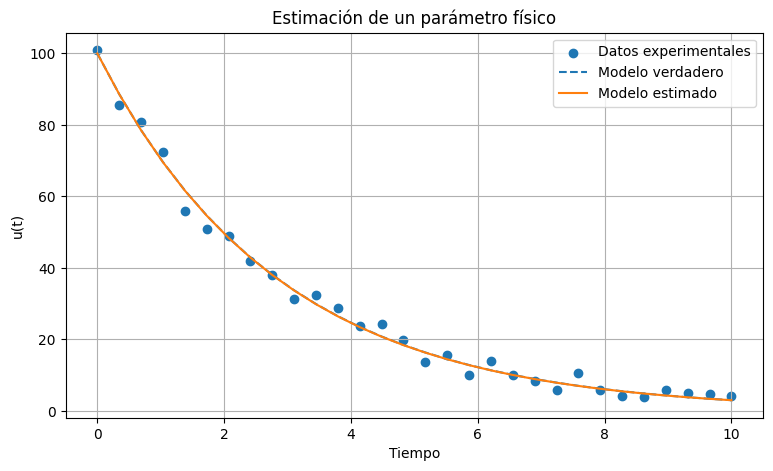

In [9]:
u_fit = modelo(t, k_hat)

plt.figure(figsize=(9, 5))

plt.scatter(
    t,
    u_obs,
    label="Datos experimentales"
)

plt.plot(
    t,
    u_real,
    linestyle="--",
    label="Modelo verdadero"
)

plt.plot(
    t,
    u_fit,
    label="Modelo estimado"
)

plt.xlabel("Tiempo")
plt.ylabel("u(t)")
plt.title("Estimación de un parámetro físico")
plt.legend()
plt.grid()
plt.show()

Esto ya se parece mucho más a un problema real de SciML que simplemente calcular una media.

# 30. Resumen conceptual

Puedes pensar en todo el bloque así:

```text
                 ESTADÍSTICA
                     │
       ┌─────────────┴─────────────┐
       │                           │
 Tendencia central             Dispersión
       │                           │
   ┌───┴────┐                  ┌───┴────┐
 Media   Mediana             Varianza   σ
       │
       ▼
    Datos
       │
       ▼
 Relaciones entre variables
       │
   ┌───┴─────────┐
 Covarianza   Correlación
       │
       ▼
    Momentos
       │
       ▼
   Distribución
       │
       ▼
   Inferencia
       │
   ┌───┴───────────────┐
Estimación       Intervalos
                    │
                    ▼
              Hipótesis
                    │
                    ▼
             Decisiones
```

| **Inicio**         | **atrás 2**                          | **Siguiente 4**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./3_2_Distribuciones.ipynb) | [⏩](./3_4_Probabilidad_para_ML.ipynb) |